# Bài tập E1: Phân loại ảnh Fashion-MNIST với Softmax, MLP và CNN
**Môn học:** Học sâu và Ứng dụng trong Thị giác Máy tính (CO5085)  
**Sinh viên:** Nguyễn Trần Phước (MSSV: 2470576)

## 1. Thiết lập Môi trường

In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = "./outputs_e1"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Device: {device}")

Device: cuda


## 2. Tải dữ liệu Fashion-MNIST & Chia tập Train / Val / Test

In [2]:
BATCH_SIZE = 64
VAL_RATIO = 0.1
DATA_DIR = "./data"

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train_ds = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True, transform=transform)

val_size = int(len(full_train_ds) * VAL_RATIO)
train_size = len(full_train_ds) - val_size
generator = torch.Generator().manual_seed(SEED)
train_ds, val_ds = random_split(full_train_ds, [train_size, val_size], generator=generator)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")

Train: 54,000 | Val: 6,000 | Test: 10,000


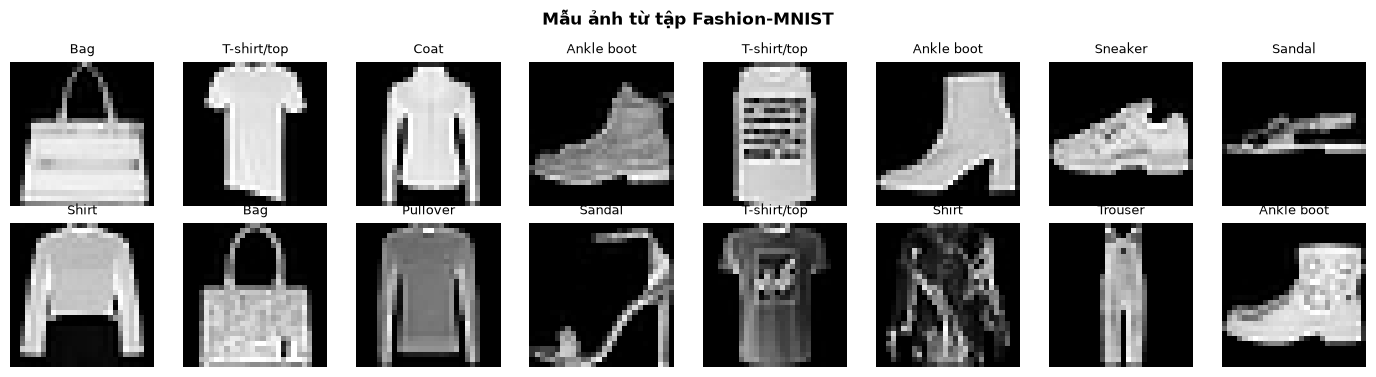

In [3]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for idx, ax in enumerate(axes.flat):
    img_np = images[idx].squeeze(0).numpy() * 0.5 + 0.5
    ax.imshow(img_np, cmap="gray")
    ax.set_title(CLASS_NAMES[labels[idx].item()], fontsize=9)
    ax.axis("off")
plt.suptitle("Mẫu ảnh từ tập Fashion-MNIST", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "sample_batch_fashion_mnist.png"), dpi=150)
plt.show()

## 3. Kiến trúc Mô hình: Softmax, MLP và CNN

In [4]:
class SoftmaxClassifier(nn.Module):
    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(28 * 28, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc(self.flatten(x))


class MLPClassifier(nn.Module):
    def __init__(self, num_classes: int = 10, dropout: float = 0.2):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(self.flatten(x))


class CNNClassifier(nn.Module):
    def __init__(self, num_classes: int = 10, dropout: float = 0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def get_model(model_name: str, num_classes: int = 10) -> nn.Module:
    name = model_name.lower()
    if name == "softmax":
        return SoftmaxClassifier(num_classes)
    if name == "mlp":
        return MLPClassifier(num_classes)
    if name == "cnn":
        return CNNClassifier(num_classes)
    raise ValueError(f"Unknown model: {model_name}")

dummy_x = torch.randn(4, 1, 28, 28)
for m_name in ["softmax", "mlp", "cnn"]:
    m = get_model(m_name)
    print(f"{m_name.upper():<8} | Output: {tuple(m(dummy_x).shape)} | Params: {count_parameters(m):,}")

SOFTMAX  | Output: (4, 10) | Params: 7,850
MLP      | Output: (4, 10) | Params: 235,914
CNN      | Output: (4, 10) | Params: 421,738


## 4. Huấn luyện và Đánh giá

In [5]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return running_loss / total, correct / total, np.array(all_preds), np.array(all_labels)

EPOCHS = 15
LR = 1e-3
models_to_run = ["softmax", "mlp", "cnn"]
history, trained_models, test_predictions, summary_results = {}, {}, {}, []

for m_name in models_to_run:
    print(f"\n{'='*50}\nTraining: {m_name.upper()}\n{'='*50}")
    model = get_model(m_name, len(CLASS_NAMES)).to(device)
    num_params = count_parameters(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)

    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_state = 0.0, None
    start_time = time.time()

    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion, device)

        h["train_loss"].append(tr_loss)
        h["val_loss"].append(va_loss)
        h["train_acc"].append(tr_acc)
        h["val_acc"].append(va_acc)

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] "
              f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc*100:.2f}% | "
              f"Val Loss: {va_loss:.4f} | Val Acc: {va_acc*100:.2f}%")

    train_time = time.time() - start_time
    history[m_name] = h

    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    trained_models[m_name] = model
    test_loss, test_acc, preds, labels = evaluate(model, test_loader, criterion, device)
    test_predictions[m_name] = (preds, labels)
    print(f"--> Test ({m_name.upper()}): Loss = {test_loss:.4f} | Acc = {test_acc*100:.2f}% | Time = {train_time:.1f}s")

    summary_results.append({
        "Model": m_name.upper(),
        "Trainable Params": num_params,
        "Best Val Acc (%)": round(best_val_acc * 100, 2),
        "Test Acc (%)": round(test_acc * 100, 2),
        "Test Loss": round(test_loss, 4),
        "Train Time (s)": round(train_time, 1)
    })


Training: SOFTMAX
Epoch [01/15] Train Loss: 0.5666 | Train Acc: 80.34% | Val Loss: 0.4967 | Val Acc: 82.77%
Epoch [02/15] Train Loss: 0.4562 | Train Acc: 84.18% | Val Loss: 0.4589 | Val Acc: 84.62%
Epoch [03/15] Train Loss: 0.4367 | Train Acc: 84.65% | Val Loss: 0.4984 | Val Acc: 82.38%
Epoch [04/15] Train Loss: 0.4271 | Train Acc: 85.08% | Val Loss: 0.4568 | Val Acc: 84.20%
Epoch [05/15] Train Loss: 0.4177 | Train Acc: 85.36% | Val Loss: 0.4513 | Val Acc: 84.37%
Epoch [06/15] Train Loss: 0.4119 | Train Acc: 85.53% | Val Loss: 0.4537 | Val Acc: 83.65%
Epoch [07/15] Train Loss: 0.4092 | Train Acc: 85.74% | Val Loss: 0.4376 | Val Acc: 84.73%
Epoch [08/15] Train Loss: 0.4045 | Train Acc: 85.82% | Val Loss: 0.4438 | Val Acc: 84.42%
Epoch [09/15] Train Loss: 0.4017 | Train Acc: 85.77% | Val Loss: 0.4492 | Val Acc: 84.40%
Epoch [10/15] Train Loss: 0.4010 | Train Acc: 85.87% | Val Loss: 0.4454 | Val Acc: 84.77%
Epoch [11/15] Train Loss: 0.3976 | Train Acc: 86.08% | Val Loss: 0.4356 | Val Acc

## 5. Kết quả So sánh & Biểu đồ Learning Curves

,Model,Trainable Params,Best Val Acc (%),Test Acc (%),Test Loss,Train Time (s)
0,SOFTMAX,7850,85.17,84.20,0.4502,240.6
1,MLP,235914,89.70,89.04,0.3044,251.8
2,CNN,421738,92.72,91.98,0.2507,245.7


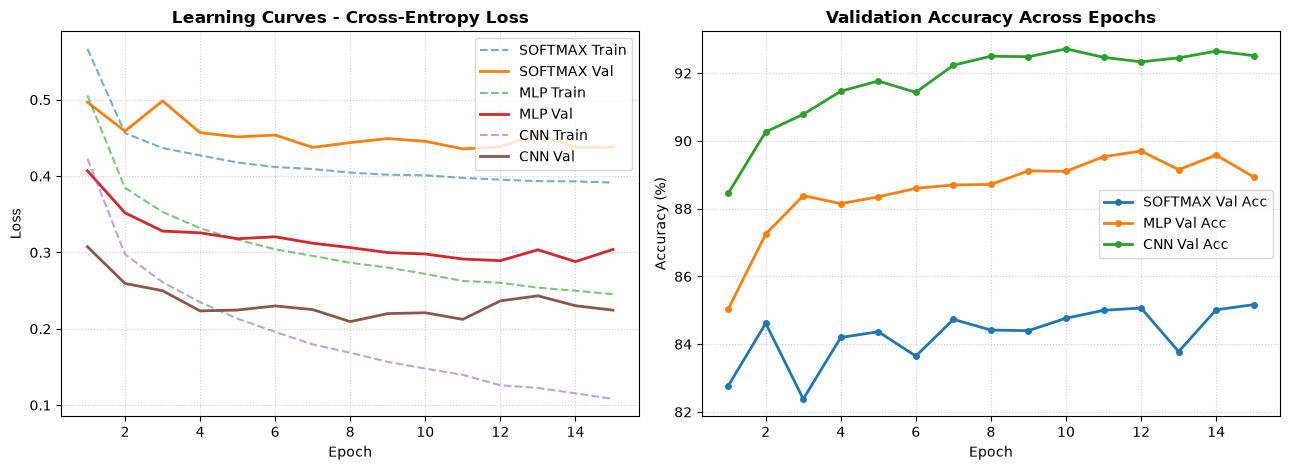

In [6]:
df_summary = pd.DataFrame(summary_results)
display(df_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, h in history.items():
    axes[0].plot(range(1, EPOCHS + 1), h["train_loss"], linestyle="--", alpha=0.6, label=f"{name.upper()} Train")
    axes[0].plot(range(1, EPOCHS + 1), h["val_loss"], linewidth=2, label=f"{name.upper()} Val")
    axes[1].plot(range(1, EPOCHS + 1), [a * 100 for a in h["val_acc"]], linewidth=2, marker="o", markersize=4, label=f"{name.upper()} Val Acc")

axes[0].set_title("Learning Curves - Cross-Entropy Loss", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].set_title("Validation Accuracy Across Epochs", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "learning_curves_fashion_mnist.png"), dpi=150)
plt.show()

## 6. Confusion Matrix & Phân tích Lỗi (Misclassified Samples)

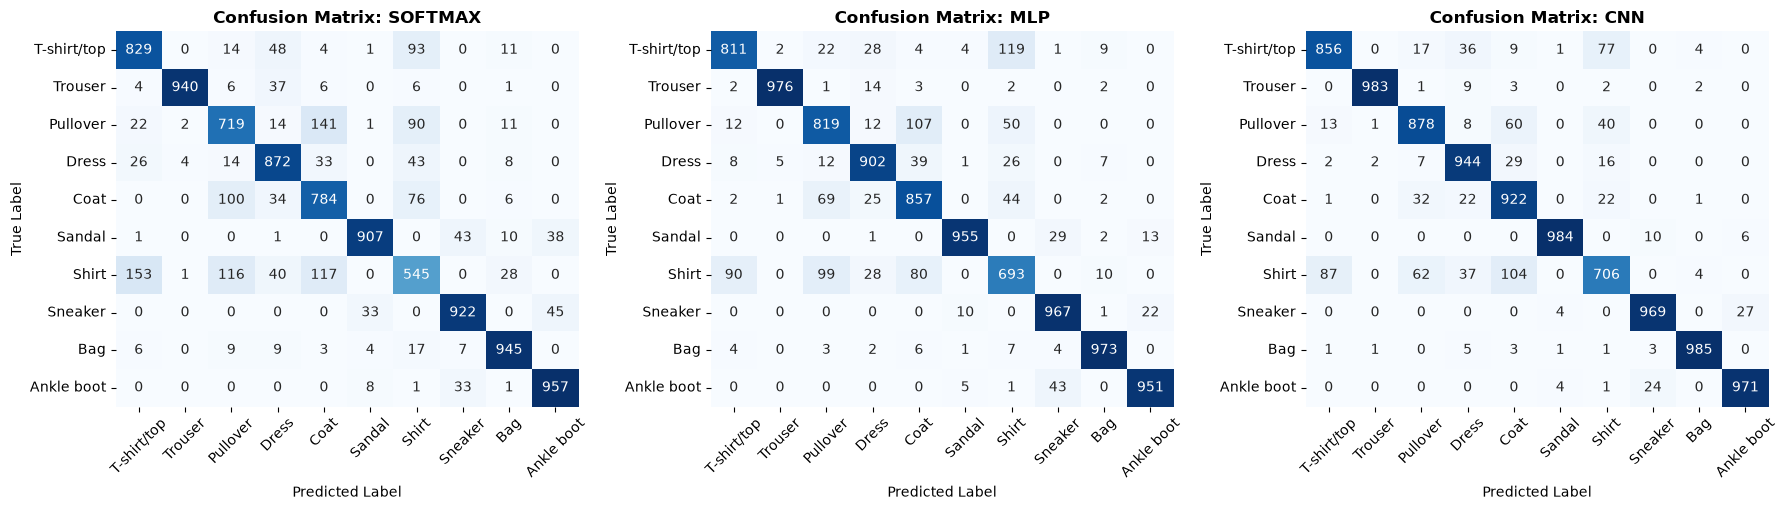


--- Classification Report: SOFTMAX ---
              precision    recall  f1-score   support

 T-shirt/top     0.7963    0.8290    0.8123      1000
     Trouser     0.9926    0.9400    0.9656      1000
    Pullover     0.7352    0.7190    0.7270      1000
       Dress     0.8265    0.8720    0.8487      1000
        Coat     0.7206    0.7840    0.7510      1000
      Sandal     0.9507    0.9070    0.9284      1000
       Shirt     0.6257    0.5450    0.5826      1000
     Sneaker     0.9174    0.9220    0.9197      1000
         Bag     0.9256    0.9450    0.9352      1000
  Ankle boot     0.9202    0.9570    0.9382      1000

    accuracy                         0.8420     10000
   macro avg     0.8411    0.8420    0.8409     10000
weighted avg     0.8411    0.8420    0.8409     10000


--- Classification Report: MLP ---
              precision    recall  f1-score   support

 T-shirt/top     0.8730    0.8110    0.8409      1000
     Trouser     0.9919    0.9760    0.9839      1000
  

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for idx, m_name in enumerate(models_to_run):
    preds, labels = test_predictions[m_name]
    cm = confusion_matrix(labels, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[idx])
    axes[idx].set_title(f"Confusion Matrix: {m_name.upper()}", fontweight="bold")
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")
    axes[idx].tick_params(axis="x", rotation=45)
    axes[idx].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrices_fashion_mnist.png"), dpi=150)
plt.show()

for m_name in models_to_run:
    preds, labels = test_predictions[m_name]
    print(f"\n--- Classification Report: {m_name.upper()} ---")
    print(classification_report(labels, preds, target_names=CLASS_NAMES, digits=4))

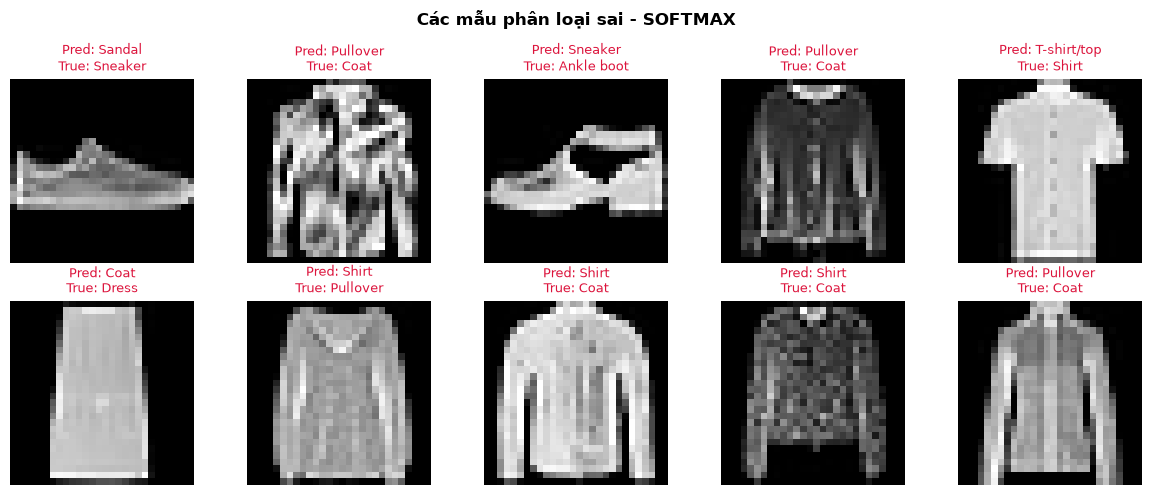

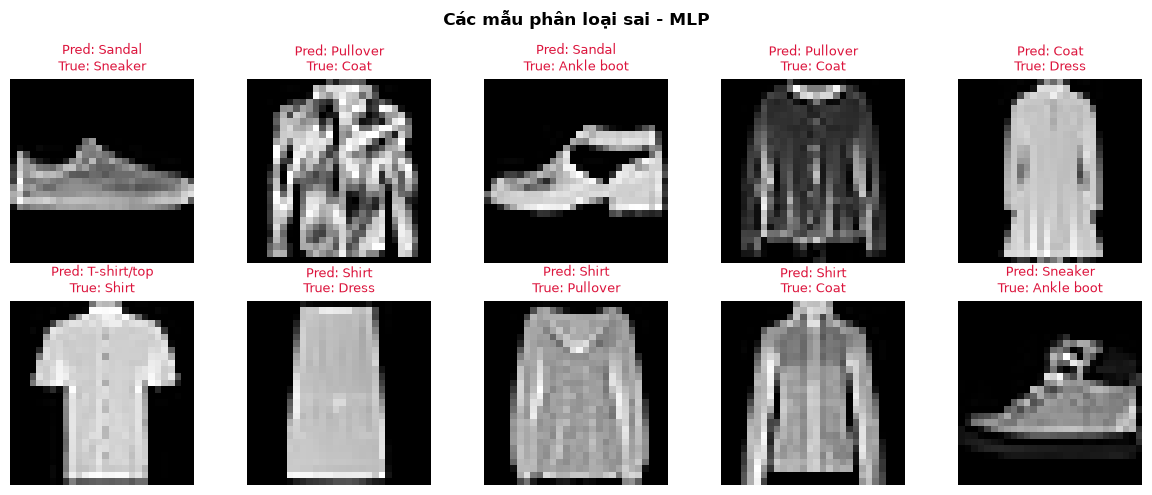

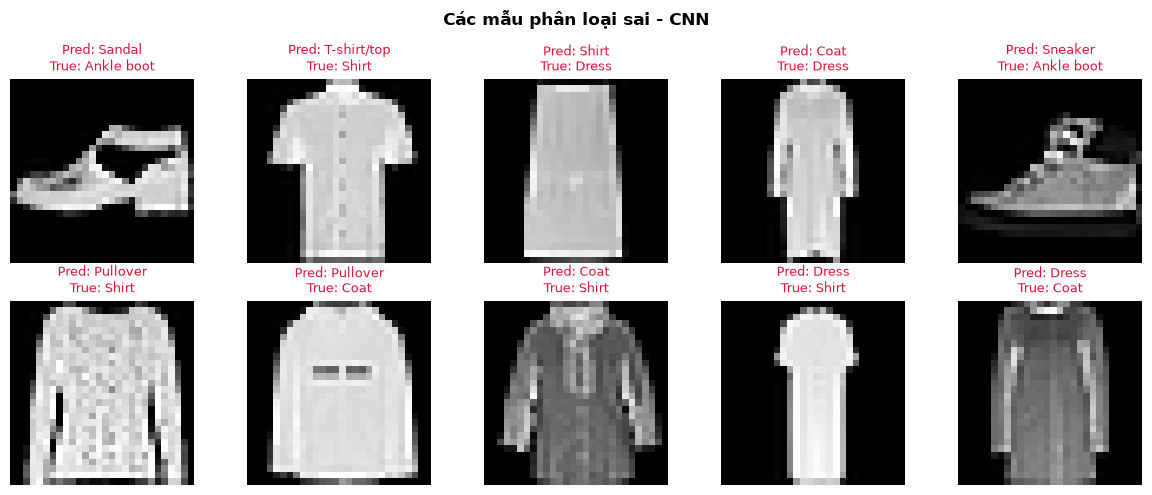

In [8]:
def show_misclassified(model, test_loader, device, model_title, save_path, num_samples=10):
    model.eval()
    mis_images, mis_preds, mis_labels = [], [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            preds = model(images).argmax(dim=1)
            mask = preds != labels
            if mask.any():
                for img, p, l in zip(images[mask], preds[mask], labels[mask]):
                    mis_images.append(img.cpu())
                    mis_preds.append(p.item())
                    mis_labels.append(l.item())
                    if len(mis_images) >= num_samples:
                        break
            if len(mis_images) >= num_samples:
                break

    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for idx, ax in enumerate(axes.flat):
        if idx >= len(mis_images):
            ax.axis("off")
            continue
        img_np = mis_images[idx].squeeze(0).numpy() * 0.5 + 0.5
        ax.imshow(img_np, cmap="gray")
        ax.set_title(f"Pred: {CLASS_NAMES[mis_preds[idx]]}\nTrue: {CLASS_NAMES[mis_labels[idx]]}", fontsize=9, color="crimson")
        ax.axis("off")

    plt.suptitle(f"Các mẫu phân loại sai - {model_title.upper()}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

for m_name in models_to_run:
    show_misclassified(
        trained_models[m_name], test_loader, device,
        model_title=m_name,
        save_path=os.path.join(OUTPUT_DIR, f"misclassified_{m_name}.png")
    )

In [9]:
import json

# 1. Lưu Config & Seed để tái lập
config_e1 = {
    "dataset": "Fashion-MNIST",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "val_ratio": VAL_RATIO,
    "epochs": EPOCHS,
    "learning_rate": LR,
    "weight_decay": 1e-4,
    "optimizer": "Adam",
    "normalize_mean": [0.5],
    "normalize_std": [0.5],
    "device": str(device)
}
with open(os.path.join(OUTPUT_DIR, "config_e1.json"), "w", encoding="utf-8") as f:
    json.dump(config_e1, f, indent=4, ensure_ascii=False)

# 2. Lưu Log lịch sử huấn luyện từng Epoch (Loss & Accuracy)
with open(os.path.join(OUTPUT_DIR, "training_log_e1.json"), "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4)

# 3. Lưu Bảng tổng hợp số liệu ra CSV
df_summary.to_csv(os.path.join(OUTPUT_DIR, "summary_results_e1.csv"), index=False)
print("Đã lưu thành công config_e1.json, training_log_e1.json và summary_results_e1.csv!")

Đã lưu thành công config_e1.json, training_log_e1.json và summary_results_e1.csv!
